<a href="https://colab.research.google.com/github/devansh98185/CSET343/blob/main/lab6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Path to dataset files: /kaggle/input/chest-xray-pneumonia


In [ ]:
import os

dataset_path = path

for root, dirs, files in os.walk(dataset_path):
    print(root, len(files))

/kaggle/input/chest-xray-pneumonia 0
/kaggle/input/chest-xray-pneumonia/chest_xray 0
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray 1
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/val 1
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/val/PNEUMONIA 9
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/val/NORMAL 9
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/test 1
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/test/PNEUMONIA 390
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/test/NORMAL 234
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/train 1
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/train/PNEUMONIA 3876
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/train/NORMAL 1342
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX 1
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray 3
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/val 1
/kaggle/input/chest-xr

In [ ]:
import os

base_dir = os.path.join(dataset_path, "chest_xray")

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")

    for cls in ["NORMAL", "PNEUMONIA"]:
        folder = os.path.join(base_dir, split, cls)

        count = len([
            f for f in os.listdir(folder)
            if f.endswith((".jpeg", ".jpg", ".png"))
        ])

        print(f"{cls}: {count}")


TRAIN
NORMAL: 1341
PNEUMONIA: 3875

VAL
NORMAL: 8
PNEUMONIA: 8

TEST
NORMAL: 234
PNEUMONIA: 390


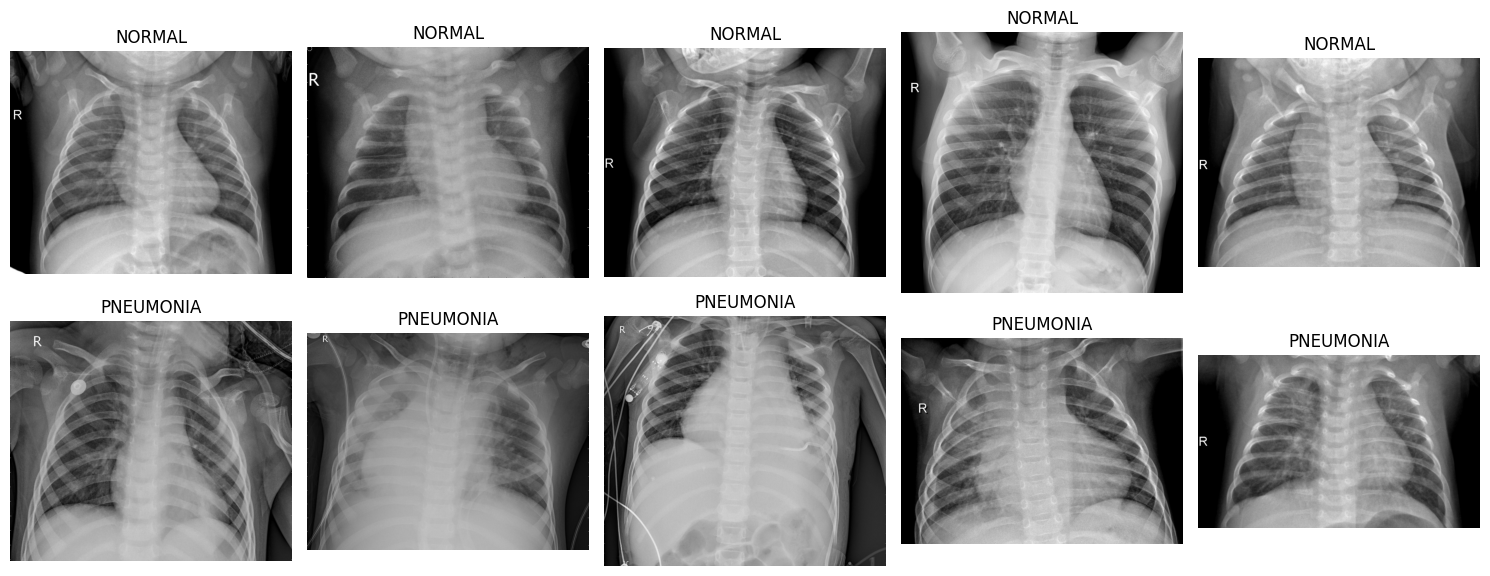

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for row, cls in enumerate(["NORMAL", "PNEUMONIA"]):

    folder = os.path.join(base_dir, "train", cls)

    samples = random.sample(os.listdir(folder), 5)

    for col, img_name in enumerate(samples):

        img_path = os.path.join(folder, img_name)

        img = Image.open(img_path)

        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].set_title(cls)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os

image_paths = []
labels = []

for split in ["train", "val", "test"]:
    for cls in ["NORMAL", "PNEUMONIA"]:

        folder = os.path.join(base_dir, split, cls)

        for img in os.listdir(folder):

            image_paths.append(os.path.join(folder, img))

            labels.append(
                0 if cls == "NORMAL" else 1
            )

print("Total images:", len(image_paths))

Total images: 5856


In [ ]:
import cv2

IMG_SIZE = 128

def preprocess_image(path):
    img = cv2.imread(path)

    img = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2GRAY
    )

    img = cv2.resize(
        img,
        (IMG_SIZE, IMG_SIZE)
    )

    return img

In [ ]:
sample = preprocess_image(image_paths[0])

print(sample.shape)

(128, 128)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print(len(X_train))
print(len(X_val))
print(len(X_test))

4099
878
879


In [ ]:
from skimage.feature import hog

def extract_hog(image):

    features = hog(
        image,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        feature_vector=True
    )

    return features

In [ ]:
from skimage.feature import local_binary_pattern
import numpy as np

def extract_lbp(image):

    lbp = local_binary_pattern(
        image,
        P=8,
        R=1,
        method='uniform'
    )

    hist, _ = np.histogram(
        lbp.ravel(),
        bins=np.arange(11),
        range=(0, 10)
    )

    hist = hist.astype("float")
    hist /= (hist.sum() + 1e-6)

    return hist

In [ ]:
from skimage.feature import graycomatrix, graycoprops
import numpy as np

def extract_glcm(image):

    glcm = graycomatrix(
        image,
        distances=[1],
        angles=[0],
        levels=256,
        symmetric=True,
        normed=True
    )

    features = [
        graycoprops(glcm, 'contrast')[0, 0],
        graycoprops(glcm, 'dissimilarity')[0, 0],
        graycoprops(glcm, 'homogeneity')[0, 0],
        graycoprops(glcm, 'energy')[0, 0],
        graycoprops(glcm, 'correlation')[0, 0],
        graycoprops(glcm, 'ASM')[0, 0]
    ]

    return np.array(features)

In [ ]:
X_train_hog = np.array([
    extract_hog(preprocess_image(path))
    for path in X_train
])

X_val_hog = np.array([
    extract_hog(preprocess_image(path))
    for path in X_val
])

X_test_hog = np.array([
    extract_hog(preprocess_image(path))
    for path in X_test
])

In [ ]:
import numpy as np

X_train_lbp = np.array([
    extract_lbp(preprocess_image(path))
    for path in X_train
])

X_val_lbp = np.array([
    extract_lbp(preprocess_image(path))
    for path in X_val
])

X_test_lbp = np.array([
    extract_lbp(preprocess_image(path))
    for path in X_test
])

In [ ]:
print("Train LBP:", X_train_lbp.shape)
print("Val LBP:", X_val_lbp.shape)
print("Test LBP:", X_test_lbp.shape)

Train LBP: (4099, 10)
Val LBP: (878, 10)
Test LBP: (879, 10)


In [ ]:
import numpy as np

X_train_glcm = np.array([
    extract_glcm(preprocess_image(path))
    for path in X_train
])


X_val_glcm = np.array([
    extract_glcm(preprocess_image(path))
    for path in X_val
])

X_test_glcm = np.array([
    extract_glcm(preprocess_image(path))
    for path in X_test
])

In [ ]:
print("HOG")
print(X_train_hog.shape, X_val_hog.shape, X_test_hog.shape)

print("\nLBP")
print(X_train_lbp.shape, X_val_lbp.shape, X_test_lbp.shape)

print("\nGLCM")
print(X_train_glcm.shape, X_val_glcm.shape, X_test_glcm.shape)

HOG
(4099, 8100) (878, 8100) (879, 8100)

LBP
(4099, 10) (878, 10) (879, 10)

GLCM
(4099, 6) (878, 6) (879, 6)


In [ ]:
import numpy as np

X_train_images = np.array([
    preprocess_image(path)
    for path in X_train
])

X_val_images = np.array([
    preprocess_image(path)
    for path in X_val
])

X_test_images = np.array([
    preprocess_image(path)
    for path in X_test
])

In [ ]:
X_train_images = X_train_images.astype("float32") / 255.0
X_val_images = X_val_images.astype("float32") / 255.0
X_test_images = X_test_images.astype("float32") / 255.0

In [ ]:
X_train_images = X_train_images[..., np.newaxis]
X_val_images = X_val_images[..., np.newaxis]
X_test_images = X_test_images[..., np.newaxis]

In [ ]:
print(X_train_images.shape)
print(X_val_images.shape)
print(X_test_images.shape)

(4099, 128, 128, 1)
(878, 128, 128, 1)
(879, 128, 128, 1)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout

def create_model():

    cnn = Sequential([

        Conv2D(
            32,
            (3,3),
            activation='relu',
            input_shape=(128,128,1)
        ),

        MaxPooling2D((2,2)),

        Conv2D(
            64,
            (3,3),
            activation='relu'
        ),

        MaxPooling2D((2,2)),

        Flatten(),

        Dense(
            128,
            activation='relu'
        ),

        Dropout(0.5),

        Dense(
            1,
            activation='sigmoid'
        )
    ])

    cnn.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return cnn

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(
    monitor='val_loss',         # Watch validation loss
    patience=5,                 # Stop after 5 epochs of no improvement
    restore_best_weights=True,  # Rollback to the best model weights
    verbose=1
)

In [ ]:
cnn_16 = create_model()

history_16 = cnn_16.fit(
    X_train_images,
    np.array(y_train),
    validation_data=(X_val_images, np.array(y_val)),
    epochs=15,
    batch_size=16,
    callbacks=[early_stopping]
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 12s 24ms/step - accuracy: 0.8814 - loss: 0.2890 - val_accuracy: 0.9248 - val_loss: 0.1920
Epoch 2/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 13s 12ms/step - accuracy: 0.9402 - loss: 0.1584 - val_accuracy: 0.9339 - val_loss: 0.1584
Epoch 3/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9502 - loss: 0.1365 - val_accuracy: 0.9351 - val_loss: 0.1542
Epoch 4/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9624 - loss: 0.1053 - val_accuracy: 0.9419 - val_loss: 0.1614
Epoch 5/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9666 - loss: 0.1000 - val_accuracy: 0.9442 - val_loss: 0.1519
Epoch 6/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9722 - loss: 0.0782 - val_accuracy: 0.9385 - val_loss: 0.1540
Epoch 7/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9761 - loss: 0.0685 - val_accuracy: 0.9419 - val_loss: 0.1796
Epoch 8/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9798 - loss: 0.0540 - val_ac

In [ ]:
best_val_acc_16 = max(history_16.history['val_accuracy'])

print("Best Validation Accuracy:", best_val_acc_16)

Best Validation Accuracy: 0.9441913366317749


In [ ]:
cnn_32 = create_model()

history_32 = cnn_32.fit(
    X_train_images,
    np.array(y_train),
    validation_data=(X_val_images, np.array(y_val)),
    epochs=15,
    batch_size=32,
    callbacks=[early_stopping]
)

Epoch 1/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 9s 40ms/step - accuracy: 0.8487 - loss: 0.3343 - val_accuracy: 0.9134 - val_loss: 0.1965
Epoch 2/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9188 - loss: 0.2011 - val_accuracy: 0.9362 - val_loss: 0.1778
Epoch 3/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9383 - loss: 0.1612 - val_accuracy: 0.9237 - val_loss: 0.2054
Epoch 4/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9439 - loss: 0.1510 - val_accuracy: 0.9305 - val_loss: 0.1574
Epoch 5/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9544 - loss: 0.1195 - val_accuracy: 0.9328 - val_loss: 0.1659
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 1.


In [ ]:
best_val_acc_32 = max(history_32.history['val_accuracy'])

print("Best Validation Accuracy:", best_val_acc_32)

Best Validation Accuracy: 0.9362186789512634


In [ ]:
cnn_64 = create_model()

history_64 = cnn_64.fit(
    X_train_images,
    np.array(y_train),
    validation_data=(X_val_images, np.array(y_val)),
    epochs=15,
    batch_size=64,
    callbacks=[early_stopping]
)

Epoch 1/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 10s 77ms/step - accuracy: 0.8268 - loss: 0.3995 - val_accuracy: 0.8895 - val_loss: 0.2667
Epoch 2/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.9236 - loss: 0.1999 - val_accuracy: 0.9328 - val_loss: 0.1660
Epoch 3/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.9266 - loss: 0.1906 - val_accuracy: 0.9385 - val_loss: 0.1623
Epoch 4/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.9505 - loss: 0.1354 - val_accuracy: 0.9248 - val_loss: 0.2561
Epoch 5/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.9502 - loss: 0.1354 - val_accuracy: 0.9442 - val_loss: 0.1426
Epoch 6/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.9597 - loss: 0.1129 - val_accuracy: 0.9271 - val_loss: 0.1746
Epoch 7/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.9510 - loss: 0.1399 - val_accuracy: 0.9339 - val_loss: 0.2028
Epoch 8/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.9636 - loss: 0.1011 - val_accuracy: 0.9442 - 

In [ ]:
best_val_acc_64 = max(history_64.history['val_accuracy'])

print("Best Validation Accuracy:", best_val_acc_64)

Best Validation Accuracy: 0.9441913366317749


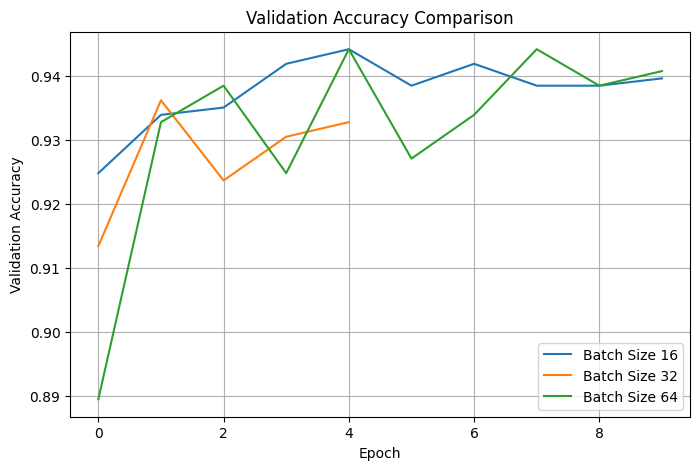

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history_16.history['val_accuracy'], label='Batch Size 16')
plt.plot(history_32.history['val_accuracy'], label='Batch Size 32')
plt.plot(history_64.history['val_accuracy'], label='Batch Size 64')

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy Comparison")
plt.legend()
plt.grid(True)

plt.show()

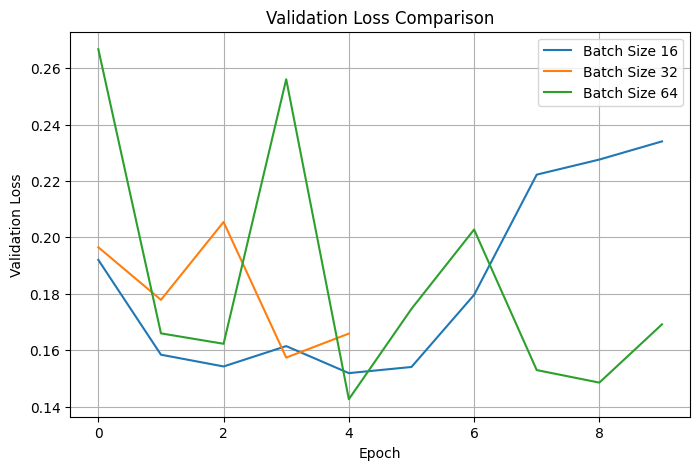

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history_16.history['val_loss'], label='Batch Size 16')
plt.plot(history_32.history['val_loss'], label='Batch Size 32')
plt.plot(history_64.history['val_loss'], label='Batch Size 64')

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Comparison")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
results = {
    "Batch Size": [16, 32, 64],
    "Best Val Accuracy": [
        max(history_16.history['val_accuracy']),
        max(history_32.history['val_accuracy']),
        max(history_64.history['val_accuracy'])
    ],
    "Best Val Loss": [
        min(history_16.history['val_loss']),
        min(history_32.history['val_loss']),
        min(history_64.history['val_loss'])
    ]
}

import pandas as pd

comparison_df = pd.DataFrame(results)
comparison_df

,Batch Size,Best Val Accuracy,Best Val Loss
0,16,0.944191,0.151860
1,32,0.936219,0.157371
2,64,0.944191,0.142605


In [ ]:
best_batch = comparison_df.loc[
    comparison_df['Best Val Accuracy'].idxmax()
]

print(best_batch)


Batch Size           16.000000
Best Val Accuracy     0.944191
Best Val Loss         0.151860
Name: 0, dtype: float64


In [ ]:
test_loss, test_acc = cnn_16.evaluate(
    X_test_images,
    np.array(y_test)
)

28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9534 - loss: 0.1242


In [ ]:
y_pred_prob = cnn_16.predict(X_test_images)

y_pred = (y_pred_prob > 0.5).astype(int)

28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step


In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.9533560864618885
Precision: 0.9746835443037974
Recall   : 0.9609984399375975
F1 Score : 0.9677926158680282


In [ ]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_test, y_pred_prob)

print("AUROC:", auc)

AUROC: 0.9861167555945936


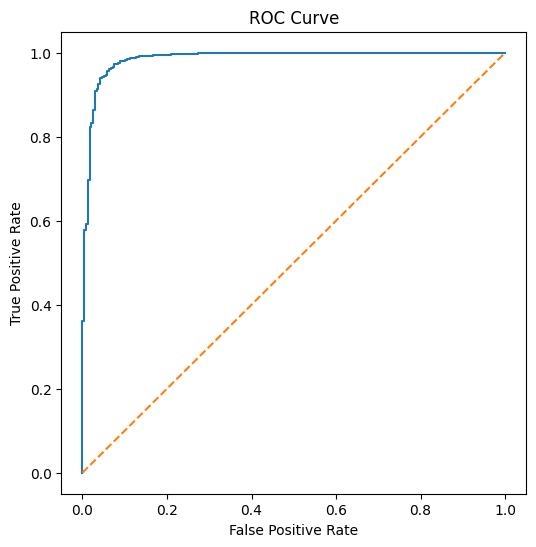

In [ ]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_pred_prob
)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr)

plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[222  16]
 [ 25 616]]


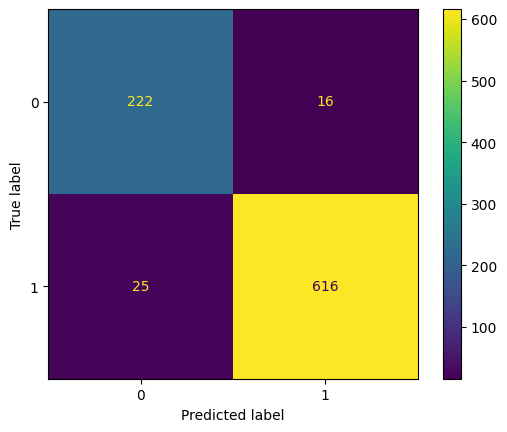

In [ ]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot()
plt.show()